**1. Imports**

In [12]:
from eeg_framework.datasets      import *
from eeg_framework.preprocessing import *
from eeg_framework.plotting      import *
from eeg_framework.features      import *
from eeg_framework.models        import *
from eeg_framework.evaluate      import *

**2. Load Data**


In [ ]:
root_dir = "data//OpenBMI MI//"
subjects = [2]
filter_param = {"l_freq": 8.0, "h_freq": 30.0, "notch_freq": None}

epochs_train = load_openbmi_mi(root_dir=root_dir, split="train", subjects=subjects, concatenate=True, **filter_param)
epochs_test  = load_openbmi_mi(root_dir=root_dir, split="test",  subjects=subjects, concatenate=True, **filter_param)

/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/datasets/openbmi_mi.py:300: RuntimeWarning: File not found: data/BCI Competition 2020 - Track#3/subj02/sess01_subj02_EEG_MI.mat
Download from https://gigadb.org/dataset/100542
  warnings.warn(str(exc), RuntimeWarning)
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/datasets/openbmi_mi.py:300: RuntimeWarning: File not found: data/BCI Competition 2020 - Track#3/subj02/sess02_subj02_EEG_MI.mat
Download from https://gigadb.org/dataset/100542
  warnings.warn(str(exc), RuntimeWarning)


RuntimeError: No epochs could be loaded — check root_dir and subject/session IDs.

In [ ]:
epochs_train

<EpochsArray | 200 events (all good), -0.5 – 4 s (baseline off), ~425.9 MiB, data loaded, with metadata,
 'right': 100
 'left': 100>

**3. Preprocessing**

In [ ]:
pipe_preprocessing = PreprocessingPipeline([
    ('crop', Crop(tmin=0.5, tmax=3.5)),
    ('rs',  Resample(100.0)),
    # ('ica', ICA(random_state=4))    
    # ...
])

epochs_train_f = pipe_preprocessing.fit_transform(epochs_train)
epochs_test_f  = pipe_preprocessing.transform(epochs_test)

[Pipeline] fit_transform → crop
[Pipeline] fit_transform → rs
[Pipeline] applying → crop
[Pipeline] applying → rs


**4. Plotting**

Topomap - Topographic Map

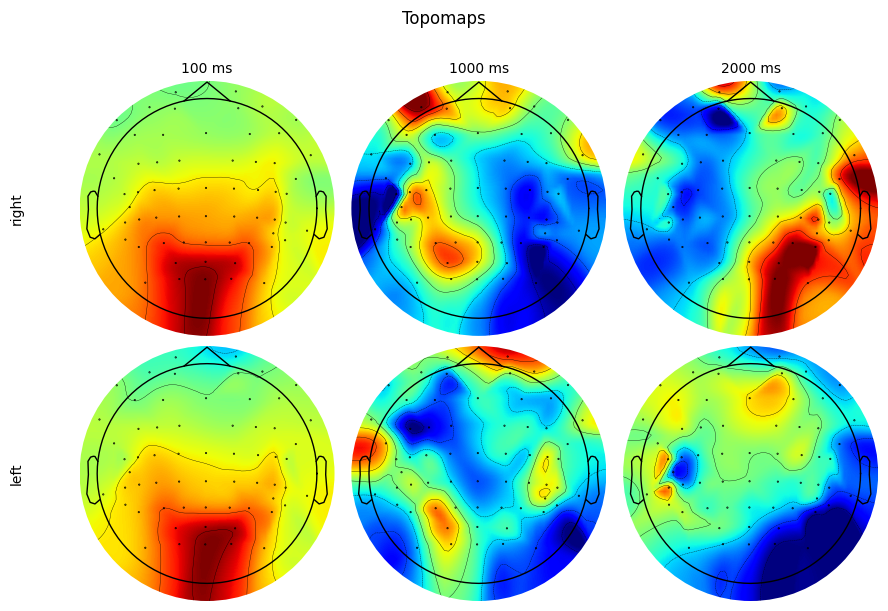

In [ ]:
times = [0.1, 1.0, 2.0] # Time [s]
# Before processing
plot_topomap(epochs_train, times = times)
# After processing
#plot_topomap(epochs_train_f, times = times)

PSD - Power Spectral Density

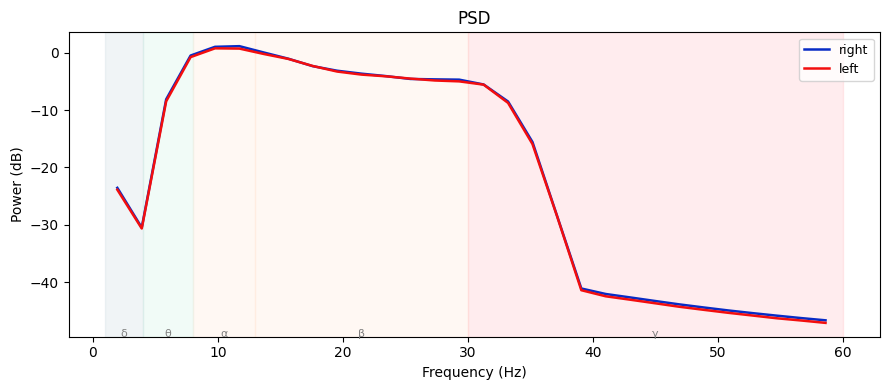

In [ ]:
# Before preprocessing
plot_psd(epochs_train)
# After preprocessing
# plot_psd(epochs_train_f)

TFR - Time-frequency

In [ ]:
# Before preprocessing
# plot_tfr(epochs_train)
# After preprocessing
#plot_tfr(epochs_train_f)

**5. Features**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle

pipe_feature = FeaturePipeline([
    ('RAW', RawFeatures(flatten=False)),
    # ...
])

X_train, y_train = pipe_feature.fit_transform(epochs_train_f)
X_test, y_test = pipe_feature.transform(epochs_test_f)


[FeaturePipeline] fitting → RAW
[FeaturePipeline] extracting → RAW
[RawFeatures] shape: (200, 62, 300)
[FeaturePipeline] extracting → RAW
[RawFeatures] shape: (200, 62, 300)


**6. Training**

In [ ]:
import os

SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import random
import numpy as np
import tensorflow as tf

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Operações determinísticas do TensorFlow
tf.config.experimental.enable_op_determinism()

# Configuration
LEARNING_RATE = 1e-3
EPOCHS = 300
VALIDATION_SPLIT = 0.2
BATCH_SIZE = 32

# Model
eegnet_config = eegnet_params_from_epochs(epochs_train_f)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

clf_model = build_eegnet(
    n_classes=2,
    compile_model=False,
    **eegnet_config
)

# Optimizer
optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

# Compile
clf_model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Training
history = clf_model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

I0000 00:00:1795021894.404141  216124 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795021894.415012  216124 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795021895.410937  216124 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795021899.245668  216124 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Epoch 1/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 121ms/step - accuracy: 0.5500 - loss: 0.6984 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 2/300


E0000 00:00:1795021902.399787  216124 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5938 - loss: 0.6862 - val_accuracy: 0.5500 - val_loss: 0.6923
Epoch 3/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5750 - loss: 0.6845 - val_accuracy: 0.5500 - val_loss: 0.6922
Epoch 4/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6250 - loss: 0.6751 - val_accuracy: 0.5500 - val_loss: 0.6922
Epoch 5/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.5562 - loss: 0.6846 - val_accuracy: 0.5500 - val_loss: 0.6923
Epoch 6/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5813 - loss: 0.6774 - val_accuracy: 0.5500 - val_loss: 0.6924
Epoch 7/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6125 - loss: 0.6770 - val_accuracy: 0.5500 - val_loss: 0.6925
Epoch 8/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6250 - loss: 0.6775 - val_accuracy: 0.5500 - val_loss: 0.6926
Epoch 9/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6375 - loss: 0.6728 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoc

**7. Evaluate**

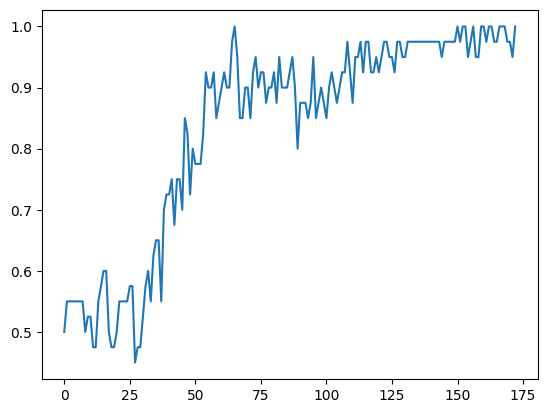

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['val_accuracy'])

5/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step 

E0000 00:00:1795021965.113673  216124 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


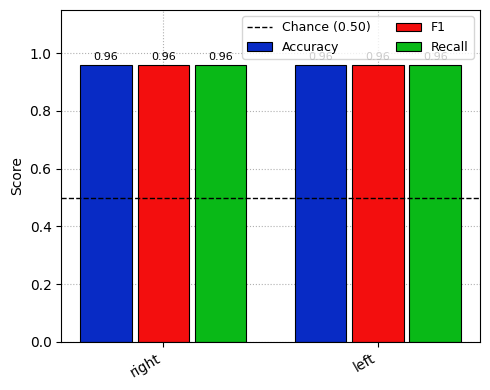

─────────────────────────────────────────────
  Accuracy        : 0.9600
  F1 (macro)      : 0.9600
  F1 (weighted)   : 0.9600
  Recall (macro)  : 0.9600
  Cohen's Kappa   : 0.9200
─────────────────────────────────────────────
  Class           Accuracy        F1    Recall
─────────────────────────────────────────────
  0                 0.9600    0.9600    0.9600
  1                 0.9600    0.9600    0.9600
─────────────────────────────────────────────


In [ ]:
class_names = list(epochs_train.event_id.keys())
y_pred = clf_model.predict(X_test)

# Metrics
compute_metrics(y_test, y_pred, class_names=class_names)
# ....

# Plots
_ = plot_metrics_bar(y_test, y_pred, class_names=class_names)

summary(y_test, y_pred)